# From messy orders to model features

One walkthrough of the whole pandas flow using the tested functions in `datapipe`: clean a messy table, aggregate and join it, then engineer features. The data is synthetic and generated with a fixed seed.

In [1]:
import sys
sys.path.insert(0, '../src')
import matplotlib.pyplot as plt
import pandas as pd
from datapipe.cleaning import make_messy_orders, clean_orders
from datapipe.aggregation import summarize_by, enrich_with_customers, make_customers, monthly_revenue_pivot, add_window_features
from datapipe.features import add_date_features, add_history_features, customer_rfm, bucket_amount

raw = make_messy_orders(300, seed=11)
raw.head()

,Order ID,Customer Name,Country,Order Date,Amount ($),Quantity
0,1000,customer 0,UAE,2026-01-17,25.58,5.0
1,1001,customer 1,NaN,2026-01-16,$400.42,1.0
2,1002,customer 2,NaN,2026-04-06,$126.78,1.0
3,1003,customer 3,Kuwait,01/03/2026,19.52,3.0
4,1004,customer 4,kuwait,2026-03-12,$235.91,2.0


## 1. The mess

Padded headers, mixed date formats, currency strings, inconsistent country labels and duplicate rows.

In [2]:
print(raw.shape)
print(raw.dtypes)
print('duplicate rows:', raw.duplicated().sum())
print(raw.iloc[:, 2].value_counts(dropna=False))

(307, 6)
 Order ID          int64
Customer Name        str
Country              str
Order Date           str
Amount ($)           str
Quantity         float64
dtype: object
duplicate rows: 7
Country
Kuwait      48
KUWAIT      44
UAE         41
kuwait      40
pakistan    36
U.A.E       35
Pakistan    32
NaN         31
Name: count, dtype: int64


## 2. Clean

`clean_orders` normalizes names, trims text, parses money and dates, standardizes countries, drops exact duplicates and flags imputed quantities.

In [3]:
clean = clean_orders(raw)
print(clean.shape)
print(clean.dtypes)
print('missing amounts kept as NaN:', clean['amount'].isna().sum())
clean.head()

(300, 7)
order_id                     int64
customer_name                  str
country                        str
order_date          datetime64[ns]
amount                     Float64
quantity                     int64
quantity_missing              bool
dtype: object
missing amounts kept as NaN: 6


,order_id,customer_name,country,order_date,amount,quantity,quantity_missing
0,1000,customer 0,UAE,2026-01-17,25.58,5,False
1,1001,customer 1,NaN,2026-01-16,400.42,1,False
2,1002,customer 2,NaN,2026-04-06,126.78,1,False
3,1003,customer 3,Kuwait,2026-03-01,19.52,3,False
4,1004,customer 4,Kuwait,2026-03-12,235.91,2,False


## 3. Aggregate and join

In [4]:
customers = make_customers(sorted(clean['customer_name'].unique()))
enriched = enrich_with_customers(clean, customers)
assert len(enriched) == len(clean)   # a left join must not add or drop rows
summarize_by(enriched, 'country')

,country,orders,priced_orders,revenue,avg_order_value
0,Kuwait,129,126,31140.66,247.148095
1,UAE,75,75,19243.72,256.582933
2,Pakistan,68,66,16590.01,251.363788
3,NaN,28,27,6977.82,258.437778


In [5]:
monthly_revenue_pivot(clean).round(0)

month,2026-01,2026-02,2026-03,2026-04,Total
country,,,,,
Kuwait,9797.0,6644.0,8121.0,6578.0,31141.0
Pakistan,5932.0,2510.0,3087.0,5061.0,16590.0
UAE,4737.0,3801.0,4736.0,5970.0,19244.0
Total,20466.0,12956.0,15943.0,17609.0,66974.0


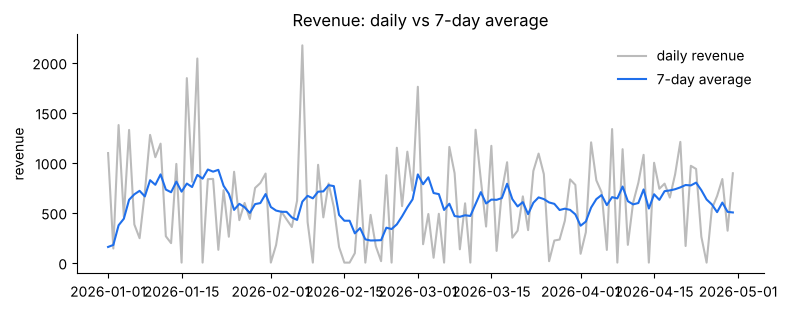

In [6]:
daily = add_window_features(clean, window_days=7)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(daily.index, daily['revenue'], color='#bbb', label='daily revenue')
ax.plot(daily.index, daily['rolling_revenue'] / 7, color='#1f6feb', label='7-day average')
ax.set_ylabel('revenue'); ax.legend(frameon=False); ax.set_title('Revenue: daily vs 7-day average')
for side in ('top', 'right'): ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

## 4. Features

History features look only at a customer's earlier orders. RFM is measured at a cut-off date, so later orders are ignored, as they would be in a real model.

In [7]:
feats = add_history_features(add_date_features(clean))
feats[['order_id', 'customer_name', 'order_date', 'amount', 'prev_amount', 'days_since_prev', 'order_number', 'is_weekend']].head(8)

,order_id,customer_name,order_date,amount,prev_amount,days_since_prev,order_number,is_weekend
0,1000,customer 0,2026-01-17,25.58,58.32,16.0,2,True
1,1001,customer 1,2026-01-16,400.42,226.9,11.0,4,False
2,1002,customer 2,2026-04-06,126.78,295.75,3.0,8,False
3,1003,customer 3,2026-03-01,19.52,45.31,4.0,6,True
4,1004,customer 4,2026-03-12,235.91,490.58,13.0,6,False
5,1005,customer 5,2026-03-14,360.34,140.04,6.0,6,True
6,1006,customer 6,2026-03-27,220.84,293.13,3.0,6,False
7,1007,customer 7,2026-01-04,185.25,<NA>,NaN,1,True


In [8]:
as_of = clean['order_date'].quantile(0.8)
rfm = customer_rfm(clean, as_of)
rfm['value_bucket'] = bucket_amount(rfm['monetary'], q=4)
print('cut-off date:', as_of.date())
rfm.sort_values('monetary', ascending=False).head(8)

cut-off date: 2026-04-09


,customer_name,recency_days,frequency,monetary,value_bucket
7,customer 15,2,8,2621.45,3
31,customer 37,0,6,2555.78,3
5,customer 13,7,8,2397.29,3
35,customer 5,4,7,2378.83,3
1,customer 1,68,7,2146.68,3
34,customer 4,2,7,2041.52,3
36,customer 6,0,8,1991.5,3
33,customer 39,16,7,1964.94,3


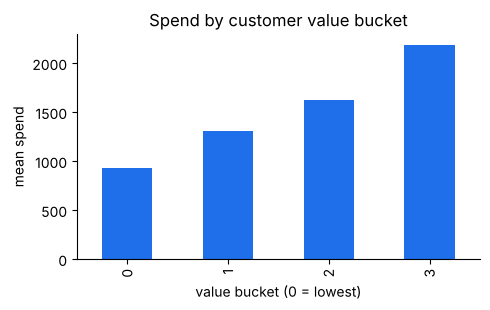

In [9]:
fig, ax = plt.subplots(figsize=(5, 3.2))
rfm.groupby('value_bucket')['monetary'].mean().plot.bar(ax=ax, color='#1f6feb')
ax.set_xlabel('value bucket (0 = lowest)'); ax.set_ylabel('mean spend'); ax.set_title('Spend by customer value bucket')
for side in ('top', 'right'): ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

## Takeaways

- Each step is a small tested function, so the notebook only shows results and the logic lives in `src/`.
- Missing amounts stay missing instead of becoming zero; imputed quantities are flagged.
- Feature code never reads the future: lags are per customer in date order and RFM stops at the cut-off.